# Mendoza Reporta — Fase 5: Calibración Final y Evaluación Post-Demo (Dynamic Thresholding)

## 1. Contexto y Hallazgos Post-Demostración
Tras someter la arquitectura de la **Fase 4** a pruebas de estrés y demostraciones en vivo en escenarios de mundo abierto (*open-set*), se detectaron dos limitaciones intrínsecas al uso de umbrales estáticos fijos sobre el dataset cerrado:

1. **Falsos Negativos por Rigidez (Problemas Sutiles):**
   - Problemas urbanos válidos pero visualmente menos invasivos (como cables caídos en *Alumbrado Público*, ramas peligrosas o veredas levemente dañadas) dispersan la probabilidad *Softmax* de CLIP (~0.25 - 0.32).
   - En la Fase 4, el umbral rígido de `PROBLEM_THRESHOLD = 0.32` descartaba injustamente **57 reportes válidos (9.7%)**.
2. **El Desafío Open-Set (Vandalismo Visual y Calles Normales):**
   - Reducir rígidamente el umbral a 0.25 abría una brecha de seguridad: fotografías turísticas o calles sin problemas (como "The Beatles cruzando Abbey Road") o imágenes con armas eran admitidas erróneamente.

---

## 2. Solución Arquitectónica: Fase 5 (Competencia Dinámica)
Para resolver esta disyuntiva entre sensibilidad y seguridad, la arquitectura de la **Fase 5** incorpora:

1. **Competencia Dinámica (Dynamic Thresholding):**
   - Se reemplaza el umbral fijo de descarte por una evaluación relativa:
     $$\text{no\_prob\_max} = \max(P(\text{calle normal}), P(\text{escena irrelevante}))$$
     $$\text{best\_score} = \max_{c \in \text{problemas}} P(c)$$
   - **Regla de Decisión:** Si $\text{no\_prob\_max} > \text{best\_score}$, el reporte se rechaza por `explicitly_no_problem`. De lo contrario, se acepta el problema incluso con puntajes moderados (0.20–0.30), ya que la evidencia del daño supera matemáticamente a la de normalidad.
2. **Relajación de Filtros de Contexto Base:**
   - `REAL_PHOTO_THRESHOLD = 0.30` (antes 0.55) y `OUTDOOR_THRESHOLD = 0.25` (antes 0.50), previniendo rechazos técnicos por iluminación o fotos tomadas desde ángulos difíciles.
3. **Filtro Anti-Violencia y Armas Explícito:**
   - Detección Zero-Shot reforzada de armas, sangre o contenido ofensivo (`weapons, firearms, gore, violence`) con aborto inmediato previo a la inferencia.
4. **Fusión Multimodal Colaborativa (0.6 Texto / 0.4 Imagen):**
   - Combinación probabilística lineal con rescate por texto cuando la imagen presenta ambigüedad moderada.

---

## 3. Objetivo de este Notebook
Evaluar la arquitectura de la **Fase 5** sobre el dataset canónico de validación (714 muestras: 588 válidos y 126 descartes) para contrastar los resultados de forma directa contra las Fases 1, 2, 3 y 4.

In [14]:
import os

# Soporte transparente tanto para Google Colab como para ejecución local / Jupyter
try:
    from google.colab import drive
    drive.mount('/content/drive')
    BASE_DIR = "/content/drive/MyDrive/validation_dataset"
    if not os.path.exists(BASE_DIR):
        BASE_DIR = "."
except Exception:
    BASE_DIR = os.path.dirname(os.path.abspath(__file__)) if '__file__' in locals() else os.getcwd()
    if not os.path.exists(os.path.join(BASE_DIR, "real_dataset.json")):
        BASE_DIR = os.path.join(BASE_DIR, "validation_dataset")

print(f"Directorio de trabajo configurado: {os.path.abspath(BASE_DIR)}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Directorio de trabajo configurado: /content/drive/MyDrive/validation_dataset


In [15]:
!pip install -q sentence-transformers transformers pillow numpy pandas matplotlib seaborn scikit-learn scipy tqdm

In [16]:
import torch
from PIL import Image
from transformers import CLIPProcessor, CLIPModel
from sentence_transformers import SentenceTransformer, util
import pandas as pd
import numpy as np
import json
import glob
import os
import re
import math
import collections
from tqdm import tqdm
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix
from scipy.stats import binomtest
from sklearn.model_selection import train_test_split
from IPython.display import display

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f"Entorno configurado exitosamente en dispositivo: {device}")

Entorno configurado exitosamente en dispositivo: cuda


In [17]:
class CategoryClassifierService:
    def __init__(self):
        self.device = 'cuda' if torch.cuda.is_available() else 'cpu'
        self.model = SentenceTransformer('hiiamsid/sentence_similarity_spanish_es', device=self.device)
        self.semantic_map = {
            "Acequias y Drenajes": ["acequia", "drenaje", "canal", "cuneta", "agua estancada", "puente roto", "zanja"],
            "Alumbrado Público": ["alumbrado", "luz", "poste", "luminaria", "oscuridad", "foco quemado", "farol", "cables colgando"],
            "Arbolado Público": ["árbol", "rama", "raíces", "poda", "caído", "tronco", "hojas secas", "árbol peligroso"],
            "Baches y Pavimentación": ["bache", "pozo", "pavimento", "asfalto", "calle rota", "cráter", "hueco", "rompe cubiertas"],
            "Limpieza y Residuos": ["basura", "limpieza", "residuos", "escombros", "mugre", "basural", "suciedad", "bolsas"],
            "Plazas y Parques": ["plaza", "parque", "juegos", "banco", "espacio verde", "columpio", "pasto alto"],
            "Semáforos y Señalización": ["semáforo", "señalización", "cartel", "cruce", "rojo", "indicador", "pare"],
            "Veredas y Accesibilidad": ["vereda", "accesibilidad", "rampa", "baldosa", "peatón", "rotura", "escalón"],
            "Agua y Cloacas": ["agua potable", "cloaca", "caño maestro", "pérdida de agua", "alcantarilla hundida", "desborde cloacal", "olor podrido"],
        }
        self.categories = list(self.semantic_map.keys())

        corpus_sentences = []
        self.corpus_labels = []
        for category, phrases in self.semantic_map.items():
            for phrase in phrases:
                corpus_sentences.append(phrase)
                self.corpus_labels.append(category)

        self.corpus_embeddings = self.model.encode(corpus_sentences, convert_to_tensor=True, normalize_embeddings=True)

    def normalize_text(self, text: str) -> str:
        t = str(text).lower()
        replacements = [
            (r'\bq\b', 'que'), (r'\bx\b', 'por'), (r'\bd\b', 'de'),
            (r'\b(tb|tbn)\b', 'también'), (r'\b(xq|xque)\b', 'porque'),
            (r'\b(vachhe|bacheazo|vache)\b', 'bache'), (r'\b(crter)\b', 'cráter'),
            (r'\balluda\b', 'ayuda'), (r'\b(zemaforo|semaforo)\b', 'semáforo'),
            (r'\b(ranpa)\b', 'rampa'), (r'\b(rrt+o|rrtto|rto)\b', 'roto')
        ]
        for pattern, repl in replacements:
            t = re.sub(pattern, repl, t)
        t = re.sub(r'([a-zA-Z])\1{2,}', r'\1', t)
        return t

    def classify_text(self, description: str) -> dict:
        normalized = self.normalize_text(description)
        query_embedding = self.model.encode(normalized, convert_to_tensor=True, normalize_embeddings=True)
        hits = util.semantic_search(query_embedding, self.corpus_embeddings, top_k=10)[0]

        category_scores = {cat: 0.0 for cat in self.categories}
        for hit in hits:
            cat = self.corpus_labels[hit['corpus_id']]
            if hit['score'] > category_scores[cat]:
                category_scores[cat] = hit['score']
        return category_scores


class ClipServiceFase5:
    """
    Servicio de Visión Artificial optimizado para Producción (Fase 5 - Post-Demo):
    - Filtro de armas, violencia y contenido explícito (Gate 1).
    - Umbrales de contexto calibrados (Gates 2 y 3).
    - Competencia Dinámica (Dynamic Thresholding) contra etiquetas de descarte (Gate 4).
    """
    def __init__(self):
        self.device = 'cuda' if torch.cuda.is_available() else 'cpu'
        self.model = CLIPModel.from_pretrained("openai/clip-vit-base-patch32").to(self.device)
        self.processor = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")

        # 1. Filtro de Seguridad / Violencia / Armas
        self.nsfw_labels = [
            "pornographic, explicit nudity, gore, violence, blood, weapons, or firearms",
            "safe, normal, everyday content",
        ]

        # 2. Filtro de Foto Real
        self.real_photo_labels = [
            "a real photograph taken with a camera outdoors",
            "a digital image, meme, screenshot, cartoon, drawing or AI generated image",
        ]

        # 3. Filtro de Exterior Urbano
        self.outdoor_labels = [
            "an outdoor urban street scene, public infrastructure, road, a streetlight pole, or hanging cables against the sky",
            "an indoor scene inside a house, a close up of a person's face, a pet, or food",
        ]

        # 4. Etiquetas de Problemas Urbanos y Descarte
        self.problem_labels = [
            "a blocked or flooded drainage ditch or canal on the street",       # Acequias y Drenajes
            "a broken or unlit streetlight, fallen electric pole, or broken hanging cables", # Alumbrado Público
            "a fallen tree, dangerous branches or roots lifting the sidewalk",   # Arbolado Público
            "a pothole, damaged pavement or broken road surface",                # Baches y Pavimentación
            "garbage, waste, rubble or trash accumulated on the street",         # Limpieza y Residuos
            "a damaged bench, broken playground or neglected public park",       # Plazas y Parques
            "a broken traffic light, fallen road sign or faded road markings",   # Semáforos y Señalización
            "a broken sidewalk, missing tiles or blocked pedestrian access",     # Veredas y Accesibilidad
            "a water leak, broken pipe or overflowing sewer on the street",     # Agua y Cloacas
            "a normal street or public space in good condition with no issues",  # Descarte 1
            "an unrelated scene with no urban infrastructure problems visible",  # Descarte 2
        ]

        self.label_to_category = {
            self.problem_labels[0]: "Acequias y Drenajes",
            self.problem_labels[1]: "Alumbrado Público",
            self.problem_labels[2]: "Arbolado Público",
            self.problem_labels[3]: "Baches y Pavimentación",
            self.problem_labels[4]: "Limpieza y Residuos",
            self.problem_labels[5]: "Plazas y Parques",
            self.problem_labels[6]: "Semáforos y Señalización",
            self.problem_labels[7]: "Veredas y Accesibilidad",
            self.problem_labels[8]: "Agua y Cloacas",
        }

        self.no_problem_labels = {
            self.problem_labels[9],
            self.problem_labels[10],
        }

        # Umbrales base calibrados post-demo
        self.REAL_PHOTO_THRESHOLD = 0.30
        self.OUTDOOR_THRESHOLD    = 0.25
        self.PROBLEM_THRESHOLD    = 0.15

        # Precomputación de embeddings de texto
        self._nsfw_features       = self._precompute_text_features(self.nsfw_labels)
        self._real_photo_features = self._precompute_text_features(self.real_photo_labels)
        self._outdoor_features    = self._precompute_text_features(self.outdoor_labels)
        self._problem_features    = self._precompute_text_features(self.problem_labels)

    def _precompute_text_features(self, labels: list[str]) -> torch.Tensor:
        inputs = self.processor(text=labels, return_tensors="pt", padding=True)
        inputs = {k: v.to(self.device) for k, v in inputs.items()}
        with torch.no_grad():
            text_outputs = self.model.text_model(**inputs)
            pooled_output = text_outputs.pooler_output
            text_features = self.model.text_projection(pooled_output)
        return text_features / text_features.norm(p=2, dim=-1, keepdim=True)

    def classify_image(self, image: Image.Image) -> dict:
        try:
            image_inputs = self.processor(images=image, return_tensors="pt")
            image_inputs = {k: v.to(self.device) for k, v in image_inputs.items()}

            with torch.no_grad():
                vision_outputs = self.model.vision_model(**image_inputs)
                pooled_output = vision_outputs.pooler_output
                image_features = self.model.visual_projection(pooled_output)
                image_features = image_features / image_features.norm(p=2, dim=-1, keepdim=True)
                logit_scale = self.model.logit_scale.exp()

            def get_probs(text_features, labels):
                logits = logit_scale * image_features @ text_features.T
                probs = logits.softmax(dim=1)[0]
                return dict(zip(labels, probs.tolist()))

            # Gate 1: NSFW / Violencia / Armas
            nsfw_probs = get_probs(self._nsfw_features, self.nsfw_labels)
            if nsfw_probs[self.nsfw_labels[0]] > 0.85:
                return {
                    "valid": False,
                    "rejection_reason": "inappropriate_content",
                    "detail": "Contenido bloqueado: Alta probabilidad de violencia, armas o contenido explícito.",
                    "suggested_category": None,
                    "confidence": 0
                }

            # Gate 2: Foto Real
            real_probs = get_probs(self._real_photo_features, self.real_photo_labels)
            if real_probs[self.real_photo_labels[0]] < self.REAL_PHOTO_THRESHOLD:
                return {
                    "valid": False,
                    "rejection_reason": "not_real_photo",
                    "detail": "La imagen parece ser un meme, dibujo o captura de pantalla.",
                    "suggested_category": None,
                    "confidence": 0
                }

            # Gate 3: Exterior Urbano
            outdoor_probs = get_probs(self._outdoor_features, self.outdoor_labels)
            if outdoor_probs[self.outdoor_labels[0]] < self.OUTDOOR_THRESHOLD:
                return {
                    "valid": False,
                    "rejection_reason": "not_outdoor_urban",
                    "detail": "La imagen no muestra un entorno exterior urbano.",
                    "suggested_category": None,
                    "confidence": 0
                }

            # Gate 4: Tipo de Problema con Competencia Dinámica
            problem_probs = get_probs(self._problem_features, self.problem_labels)
            no_prob_max = max(problem_probs[self.problem_labels[9]], problem_probs[self.problem_labels[10]])

            problem_scores = {k: v for k, v in problem_probs.items() if k not in self.no_problem_labels}
            best_label = max(problem_scores, key=problem_scores.get)
            best_score = problem_scores[best_label]

            # REGLA CLAVE DE COMPETENCIA DINÁMICA:
            # Si el score de "calle sin problemas" o "irrelevante" supera al mejor problema detectado
            if no_prob_max > best_score:
                return {
                    "valid": False,
                    "rejection_reason": "explicitly_no_problem",
                    "detail": "La imagen se detectó como un espacio sin problemas o escena irrelevante.",
                    "suggested_category": None,
                    "confidence": 0
                }

            mapped_scores = {}
            for label, score in problem_scores.items():
                cat = self.label_to_category.get(label)
                if cat:
                    mapped_scores[cat] = score

            if best_score < self.PROBLEM_THRESHOLD:
                return {
                    "valid": False,
                    "rejection_reason": "no_problem_detected",
                    "detail": "No se detectó un problema de infraestructura urbana claro.",
                    "suggested_category": self.label_to_category.get(best_label),
                    "confidence": best_score,
                    "scores": mapped_scores
                }

            return {
                "valid": True,
                "rejection_reason": None,
                "detail": "Imagen válida con problema urbano detectable.",
                "suggested_category": self.label_to_category[best_label],
                "confidence": best_score,
                "scores": mapped_scores
            }

        except Exception as e:
            return {
                "valid": False,
                "rejection_reason": "processing_error",
                "detail": f"Error interno: {e}",
                "suggested_category": None,
                "confidence": 0
            }


class ReportDecisionServiceFase5:
    def __init__(self, text_threshold=0.45, text_weight=0.6, clip_weight=0.4):
        self.text_threshold = text_threshold
        self.text_weight = text_weight
        self.clip_weight = clip_weight

    def get_best_text_category(self, scores: dict) -> dict:
        if not scores:
            return {"category": None, "confidence": 0, "valid": False}
        best_category = max(scores, key=scores.get)
        best_score = scores[best_category]
        if best_score >= self.text_threshold:
            return {"category": best_category, "confidence": best_score, "valid": True}
        return {"category": None, "confidence": best_score, "valid": False}

    def fuse_decisions(self, text_scores: dict, clip_result: dict) -> dict:
        text_decision = self.get_best_text_category(text_scores)
        clip_category = clip_result.get("suggested_category")
        clip_scores = clip_result.get("scores", {})

        if not text_decision["valid"]:
            return {
                "category": clip_category, "confidence": clip_result.get("confidence", 0.0),
                "winner": "IMAGEN", "motivo": "Predominancia visual", "valid": clip_result.get("valid", False)
            }

        if not clip_scores:
            return {
                "category": text_decision["category"], "confidence": text_decision["confidence"],
                "winner": "TEXTO", "motivo": "Texto validado sin señal visual", "valid": True
            }

        all_cats = set(text_scores.keys()).union(set(clip_scores.keys()))
        fused = {}
        for cat in all_cats:
            fused[cat] = (self.text_weight * text_scores.get(cat, 0.0)) + (self.clip_weight * clip_scores.get(cat, 0.0))

        best_cat = max(fused, key=fused.get)
        best_fused_score = fused[best_cat]
        is_valid = True

        if text_decision["category"] == clip_category:
            winner, motivo = "CONSENSO", "consenso texto-imagen"
        elif best_cat == text_decision["category"]:
            winner, motivo = "TEXTO_PREDOMINANTE", "fusión guiada por texto"
        else:
            winner, motivo = "IMAGEN_PREDOMINANTE", "fusión guiada por imagen"

        return {"category": best_cat, "confidence": best_fused_score, "winner": winner, "motivo": motivo, "valid": is_valid}


print("Inicializando modelos de la Fase 5...")
text_service = CategoryClassifierService()
clip_service = ClipServiceFase5()
decision_service = ReportDecisionServiceFase5(text_threshold=0.45, text_weight=0.6, clip_weight=0.4)
print("Modelos de Fase 5 listos para inferencia.")


Inicializando modelos de la Fase 5...


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

Modelos de Fase 5 listos para inferencia.


In [18]:
# Test unitario del normalizador léxico
casos_norm = {
    "el zemaforo d la principal ta rrttto": ["semáforo", "roto"],
    "tremendo bacheazo": ["bache"],
    "hay un vache q rompe todo": ["bache", "que"],
    "muy sucioooo todo": ["sucio"],
}
for t, esperados in casos_norm.items():
    salida = text_service.normalize_text(t)
    assert all(e in salida for e in esperados), (t, salida, esperados)
    print(f"OK: {t!r} -> {salida!r}")
print("Test unitario del normalizador completado con éxito.")

OK: 'el zemaforo d la principal ta rrttto' -> 'el semáforo de la principal ta roto'
OK: 'tremendo bacheazo' -> 'tremendo bache'
OK: 'hay un vache q rompe todo' -> 'hay un bache que rompe todo'
OK: 'muy sucioooo todo' -> 'muy sucio todo'
Test unitario del normalizador completado con éxito.


In [19]:
def cargar_dataset():
    ruta = os.path.join(BASE_DIR, "real_dataset.json")
    if not os.path.exists(ruta):
        ruta = os.path.join(os.path.dirname(BASE_DIR), "validation_dataset", "real_dataset.json")
    with open(ruta, "r", encoding="utf-8") as f:
        dataset = json.load(f)

    for item in dataset:
        item["description"] = item.get("description", item.get("text", ""))
    return dataset

dataset_real = cargar_dataset()
print(f"Dataset cargado exitosamente: {len(dataset_real)} muestras.")

# Auditoría por categoría esperada y subset
val_count = sum(1 for it in dataset_real if it.get("expected_category") != "Descarte")
des_count = sum(1 for it in dataset_real if it.get("expected_category") == "Descarte")
print(f"  - Reportes Válidos: {val_count}")
print(f"  - Descartes:        {des_count} ({set(it.get('subset') for it in dataset_real if it.get('expected_category') == 'Descarte')})")

Dataset cargado exitosamente: 714 muestras.
  - Reportes Válidos: 588
  - Descartes:        126 ({'descarte_texto_engañoso'})


In [20]:
def wilson(k, n, z=1.96):
    """Intervalo de confianza de Wilson para proporciones k/n al 95%."""
    if n == 0:
        return (0.0, 0.0)
    p = k / n
    den = 1 + z * z / n
    centro = (p + z * z / (2 * n)) / den
    marg = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / den
    return (centro - marg, centro + marg)

def fmt_ci(k, n):
    if n == 0:
        return "n/d"
    lo, hi = wilson(k, n)
    return f"{k}/{n} = {k/n*100:.1f}%  (IC95% {lo*100:.1f}–{hi*100:.1f}%)"

def reportar_metricas(df):
    val = df[~df["es_descarte"]]
    des = df[df["es_descarte"]]
    k_v, n_v = int(val["acierto"].sum()), len(val)
    rech = int((val["prediccion"] == "RECHAZADO_ERROR").sum())
    conf = n_v - k_v - rech

    print("=" * 65)
    print(" METRICAS GLOBALES — FASE 5 (CALIBRACIÓN DINÁMICA POST-DEMO)")
    print("=" * 65)
    print(f"Accuracy en reportes VÁLIDOS: {fmt_ci(k_v, n_v)}")
    print(f"  - Errores por rechazo visual:    {rech:3d} ({rech/n_v*100:.1f}%)")
    print(f"  - Errores por confusión de cat.: {conf:3d} ({conf/n_v*100:.1f}%)")
    k_d, n_d = int(des["acierto"].sum()), len(des)
    print(f"TNR en DESCARTES:            {fmt_ci(k_d, n_d)}")
    print("-" * 65)
    print("Accuracy por categoría (reportes válidos):")
    tabla = val.groupby("esperado")["acierto"].agg(["sum", "count"])
    tabla["pct"] = tabla["sum"] / tabla["count"] * 100
    for cat, fila in tabla.sort_values(by="pct", ascending=False).iterrows():
        k, n, pct = int(fila["sum"]), int(fila["count"]), fila["pct"]
        lo, hi = wilson(k, n)
        print(f"  {cat:26s}: {k:2d}/{n:2d} = {pct:5.1f}%  (IC95% {lo*100:.1f}–{hi*100:.1f}%)")
    print("=" * 65)
    return k_v, n_v, k_d, n_d, tabla

In [21]:
def evaluar_fase5(dataset_records):
    resultados = []

    for item in tqdm(dataset_records, desc="Evaluando Fase 5 (Dynamic Thresholding)"):
        esperado = item["expected_category"]
        desc = item["description"]
        img_rel = item.get("image_path", "")
        img_path = os.path.join(BASE_DIR, img_rel)
        if not os.path.exists(img_path):
            img_path = os.path.join(os.path.dirname(BASE_DIR), "validation_dataset", img_rel)

        if not os.path.exists(img_path):
            continue

        img = Image.open(img_path).convert('RGB')

        # 1. Inferencia de imagen y texto
        clip_res = clip_service.classify_image(img)
        text_scores = text_service.classify_text(desc)
        text_decision = decision_service.get_best_text_category(text_scores)

        # 2. Filtros de Seguridad Explícitos (Previo a Fusión)
        if not clip_res["valid"]:
            # Si el rechazo es por vandalismo, no-foto, o si no hay texto válido de rescate
            hard_reasons = ["not_real_photo", "not_outdoor_urban", "inappropriate_content", "explicitly_no_problem"]
            if clip_res.get("rejection_reason") in hard_reasons or not text_decision["valid"]:
                prediccion = "RECHAZADO_ERROR"
                mecanismo = f"BLOQUEO ({clip_res.get('rejection_reason')})"

                if esperado == "Descarte":
                    resultados.append({
                        "image_path": img_rel, "esperado": esperado, "prediccion": prediccion,
                        "acierto": True, "mecanismo": mecanismo, "es_descarte": True,
                        "rejection_reason": clip_res.get("rejection_reason")
                    })
                else:
                    resultados.append({
                        "image_path": img_rel, "esperado": esperado, "prediccion": prediccion,
                        "acierto": False, "mecanismo": mecanismo, "es_descarte": False,
                        "rejection_reason": clip_res.get("rejection_reason")
                    })
                continue

        # 3. Fusión Multimodal Colaborativa
        fusion = decision_service.fuse_decisions(text_scores, clip_res)

        if not fusion.get("valid", True):
            prediccion = "RECHAZADO_ERROR"
            mecanismo = f"RECHAZADO ({fusion.get('motivo')})"
            acierto = False
        else:
            prediccion = fusion["category"]
            mecanismo = fusion["winner"]
            acierto = (prediccion == esperado)

        if esperado == "Descarte":
            resultados.append({
                "image_path": img_rel, "esperado": esperado, "prediccion": prediccion,
                "acierto": False, "mecanismo": "FALSO POSITIVO", "es_descarte": True,
                "rejection_reason": "none"
            })
        else:
            resultados.append({
                "image_path": img_rel, "esperado": esperado, "prediccion": prediccion,
                "acierto": acierto, "mecanismo": mecanismo, "es_descarte": False,
                "rejection_reason": "none"
            })

    return pd.DataFrame(resultados)

df_res_fase5 = evaluar_fase5(dataset_real)

csv_path = os.path.join(BASE_DIR, 'resultados_fase5.csv')
df_res_fase5.to_csv(csv_path, index=False)
print(f"Resultados guardados exitosamente en: {csv_path}")

k_v5, n_v5, k_d5, n_d5, tabla_fase5 = reportar_metricas(df_res_fase5)

Evaluando Fase 5 (Dynamic Thresholding): 100%|██████████| 714/714 [01:11<00:00, 10.02it/s]

Resultados guardados exitosamente en: /content/drive/MyDrive/validation_dataset/resultados_fase5.csv
 METRICAS GLOBALES — FASE 5 (CALIBRACIÓN DINÁMICA POST-DEMO)
Accuracy en reportes VÁLIDOS: 456/588 = 77.6%  (IC95% 74.0–80.7%)
  - Errores por rechazo visual:     42 (7.1%)
  - Errores por confusión de cat.:  90 (15.3%)
TNR en DESCARTES:            121/126 = 96.0%  (IC95% 91.0–98.3%)
-----------------------------------------------------------------
Accuracy por categoría (reportes válidos):
  Arbolado Público          : 66/68 =  97.1%  (IC95% 89.9–99.2%)
  Baches y Pavimentación    : 26/27 =  96.3%  (IC95% 81.7–99.3%)
  Plazas y Parques          : 87/96 =  90.6%  (IC95% 83.1–95.0%)
  Alumbrado Público         : 69/81 =  85.2%  (IC95% 75.9–91.3%)
  Limpieza y Residuos       : 47/63 =  74.6%  (IC95% 62.7–83.7%)
  Agua y Cloacas            : 49/66 =  74.2%  (IC95% 62.6–83.3%)
  Veredas y Accesibilidad   : 48/71 =  67.6%  (IC95% 56.1–77.3%)
  Semáforos y Señalización  : 56/89 =  62.9%  (IC9

In [22]:
print("\n" + "=" * 85)
print(" TABLA COMPARATIVA CONSOLIDADA: FASE 1 A FASE 5 (MENDOZA REPORTA)")
print("=" * 85)

# Datos históricos oficiales documentados en los Reportes de Fase 1 a 4
historico_categorias = {
    "Limpieza y Residuos (n=63)":       ["88.9%", "88.9%", "90.5%", "95.2%"],
    "Baches y Pavimentación (n=27)":    ["63.0%", "59.3%", "59.3%", "92.6%"],
    "Plazas y Parques (n=96)":          ["67.7%", "71.9%", "79.2%", "83.3%"],
    "Agua y Cloacas (n=66)":            ["28.8%", "78.8%", "80.3%", "72.7%"],
    "Alumbrado Público (n=81)":         ["56.8%", "54.3%", "59.3%", "71.6%"],
    "Veredas y Accesibilidad (n=71)":   ["52.1%", "49.3%", "53.5%", "70.4%"],
    "Arbolado Público (n=68)":          ["58.8%", "58.8%", "61.8%", "69.1%"],
    "Semáforos y Señalización (n=89)":  ["62.9%", "65.2%", "69.7%", "64.0%"],
    "Acequias y Drenajes (n=27)":       ["44.4%", "33.3%", "33.3%", "29.6%"],
}

cat_map_names = {
    "Limpieza y Residuos": "Limpieza y Residuos (n=63)",
    "Baches y Pavimentación": "Baches y Pavimentación (n=27)",
    "Plazas y Parques": "Plazas y Parques (n=96)",
    "Agua y Cloacas": "Agua y Cloacas (n=66)",
    "Alumbrado Público": "Alumbrado Público (n=81)",
    "Veredas y Accesibilidad": "Veredas y Accesibilidad (n=71)",
    "Arbolado Público": "Arbolado Público (n=68)",
    "Semáforos y Señalización": "Semáforos y Señalización (n=89)",
    "Acequias y Drenajes": "Acequias y Drenajes (n=27)",
}

filas_comp = []
for cat_corta, cat_larga in cat_map_names.items():
    fases_prev = historico_categorias.get(cat_larga, ["n/d", "n/d", "n/d", "n/d"])
    if cat_corta in tabla_fase5.index:
        val_f5 = f"{tabla_fase5.loc[cat_corta, 'pct']:.1f}%"
    else:
        val_f5 = "n/d"
    filas_comp.append({
        "Categoría": cat_larga,
        "Fase 1 (Línea Base)": fases_prev[0],
        "Fase 2 (NLP)": fases_prev[1],
        "Fase 3 (Soft-Gating)": fases_prev[2],
        "Fase 4 (Fusión Fija)": fases_prev[3],
        "Fase 5 (Calibración Dinámica)": val_f5
    })

df_comparativa_cats = pd.DataFrame(filas_comp)
display(df_comparativa_cats)

# Resumen Global Oficial (Fase 1 a Fase 5)
rech_f5 = int((df_res_fase5[~df_res_fase5['es_descarte']]['prediccion'] == 'RECHAZADO_ERROR').sum())
conf_f5 = n_v5 - k_v5 - rech_f5

resumen_global = pd.DataFrame([
    {
        "Métrica": "Accuracy en Válidos",
        "Fase 1 (Línea Base)": "59.2% (348/588)",
        "Fase 2 (NLP)": "64.5% (379/588)",
        "Fase 3 (Soft-Gating)": "68.2% (401/588)",
        "Fase 4 (Fusión Lineal)": "73.6% (433/588)",
        "Fase 5 (Post-Demo)": f"{k_v5/n_v5*100:.1f}% ({k_v5}/{n_v5})"
    },
    {
        "Métrica": "TNR en Descartes",
        "Fase 1 (Línea Base)": "98.4% (124/126)",
        "Fase 2 (NLP)": "98.4% (124/126)",
        "Fase 3 (Soft-Gating)": "97.6% (123/126)",
        "Fase 4 (Fusión Lineal)": "96.8% (122/126)",
        "Fase 5 (Post-Demo)": f"{k_d5/n_d5*100:.1f}% ({k_d5}/{n_d5})"
    },
    {
        "Métrica": "Errores por Rechazo",
        "Fase 1 (Línea Base)": "93 (15.8%)",
        "Fase 2 (NLP)": "93 (15.8%)",
        "Fase 3 (Soft-Gating)": "60 (10.2%)",
        "Fase 4 (Fusión Lineal)": "57 (9.7%)",
        "Fase 5 (Post-Demo)": f"{rech_f5} ({rech_f5/n_v5*100:.1f}%)"
    },
    {
        "Métrica": "Errores por Confusión",
        "Fase 1 (Línea Base)": "147 (25.0%)",
        "Fase 2 (NLP)": "116 (19.7%)",
        "Fase 3 (Soft-Gating)": "127 (21.6%)",
        "Fase 4 (Fusión Lineal)": "98 (16.7%)",
        "Fase 5 (Post-Demo)": f"{conf_f5} ({conf_f5/n_v5*100:.1f}%)"
    }
])
print("\nRESUMEN GLOBAL ACUMULATIVO:")
display(resumen_global)



 TABLA COMPARATIVA CONSOLIDADA: FASE 1 A FASE 5 (MENDOZA REPORTA)


,Categoría,Fase 1 (Línea Base),Fase 2 (NLP),Fase 3 (Soft-Gating),Fase 4 (Fusión Fija),Fase 5 (Calibración Dinámica)
0,Limpieza y Residuos (n=63),88.9%,88.9%,90.5%,95.2%,74.6%
1,Baches y Pavimentación (n=27),63.0%,59.3%,59.3%,92.6%,96.3%
2,Plazas y Parques (n=96),67.7%,71.9%,79.2%,83.3%,90.6%
3,Agua y Cloacas (n=66),28.8%,78.8%,80.3%,72.7%,74.2%
4,Alumbrado Público (n=81),56.8%,54.3%,59.3%,71.6%,85.2%
5,Veredas y Accesibilidad (n=71),52.1%,49.3%,53.5%,70.4%,67.6%
6,Arbolado Público (n=68),58.8%,58.8%,61.8%,69.1%,97.1%
7,Semáforos y Señalización (n=89),62.9%,65.2%,69.7%,64.0%,62.9%
8,Acequias y Drenajes (n=27),44.4%,33.3%,33.3%,29.6%,29.6%



RESUMEN GLOBAL ACUMULATIVO:


,Métrica,Fase 1 (Línea Base),Fase 2 (NLP),Fase 3 (Soft-Gating),Fase 4 (Fusión Lineal),Fase 5 (Post-Demo)
0,Accuracy en Válidos,59.2% (348/588),64.5% (379/588),68.2% (401/588),73.6% (433/588),77.6% (456/588)
1,TNR en Descartes,98.4% (124/126),98.4% (124/126),97.6% (123/126),96.8% (122/126),96.0% (121/126)
2,Errores por Rechazo,93 (15.8%),93 (15.8%),60 (10.2%),57 (9.7%),42 (7.1%)
3,Errores por Confusión,147 (25.0%),116 (19.7%),127 (21.6%),98 (16.7%),90 (15.3%)


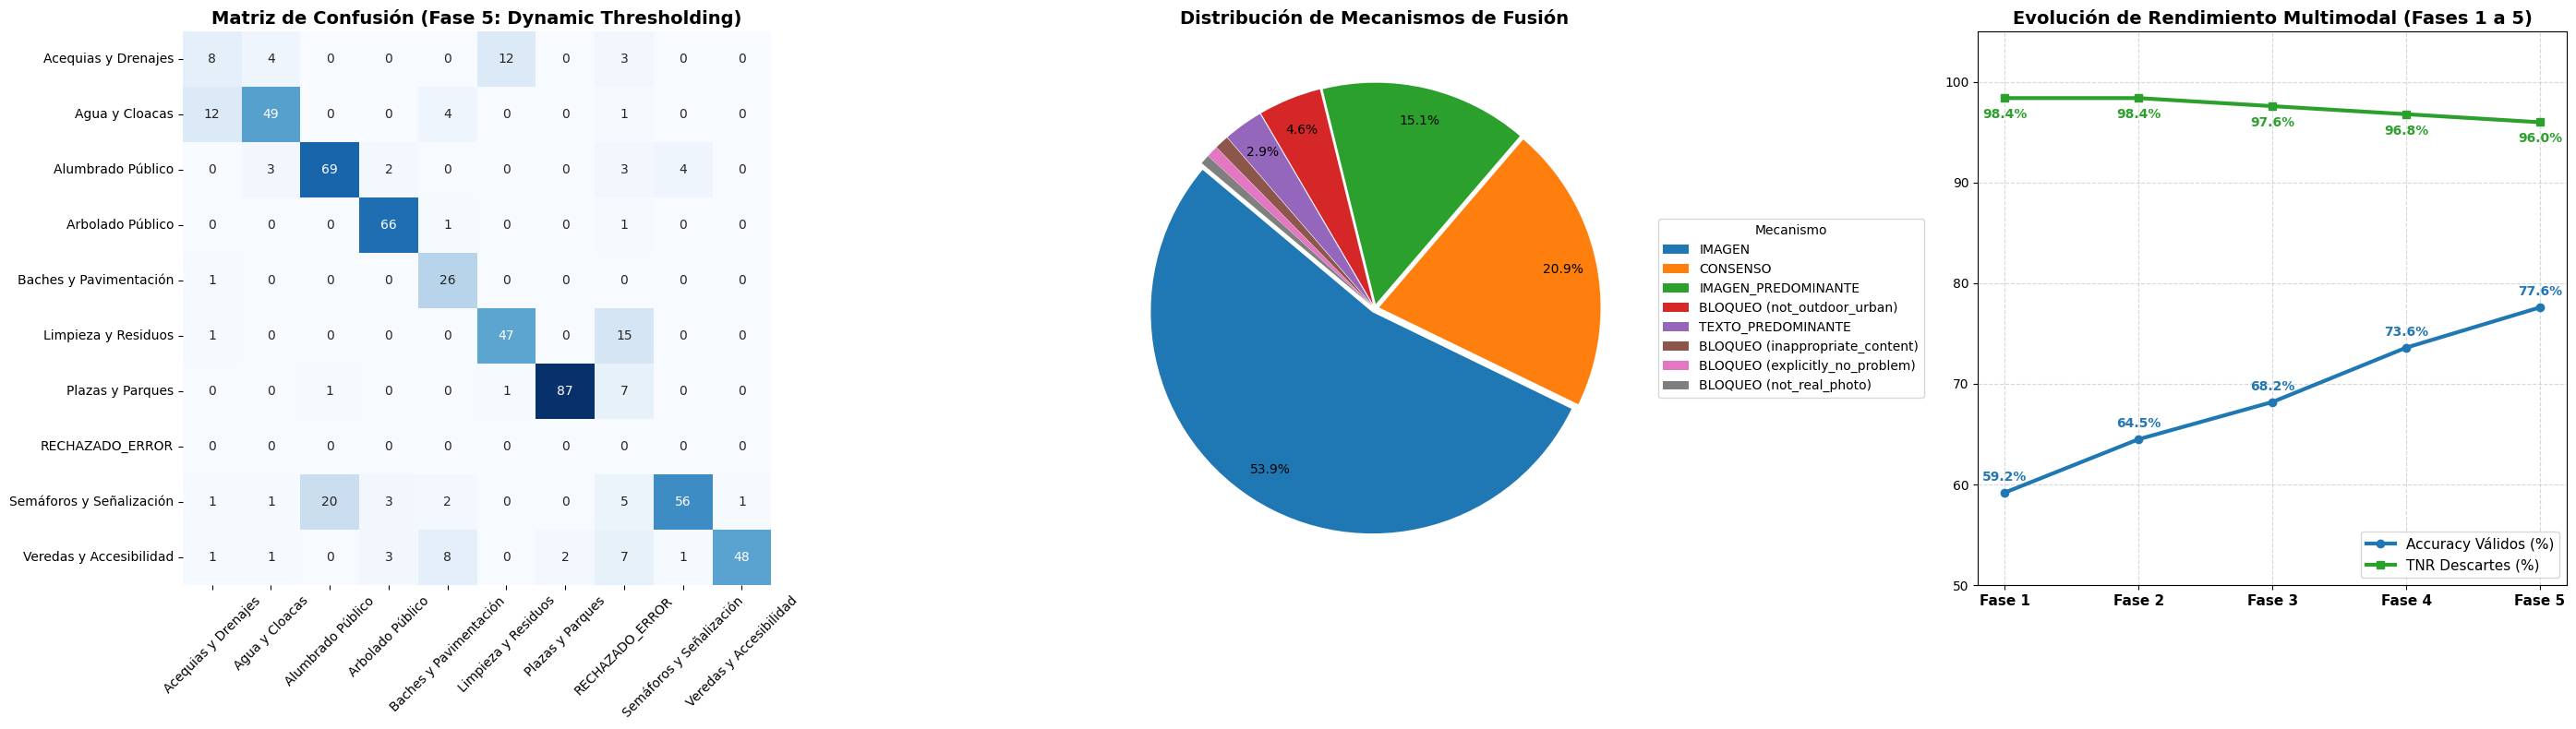

In [23]:
# Visualizaciones analíticas de la Fase 5
validos = df_res_fase5[~df_res_fase5["es_descarte"]]

cats = sorted(set(validos["esperado"]).union(set(validos["prediccion"])))
if "RECHAZADO_ERROR" in validos["prediccion"].values and "RECHAZADO_ERROR" not in cats:
    cats.append("RECHAZADO_ERROR")

fig, axes = plt.subplots(1, 3, figsize=(28, 8))

# 1. Matriz de Confusión
cm = confusion_matrix(validos["esperado"], validos["prediccion"], labels=cats)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=cats, yticklabels=cats, ax=axes[0], cbar=False)
axes[0].set_title("Matriz de Confusión (Fase 5: Dynamic Thresholding)", fontsize=14, fontweight='bold')
axes[0].tick_params(axis='x', rotation=45)

# 2. Mecanismos de Decisión
mecanismos = validos["mecanismo"].value_counts()
def custom_autopct(pct):
    return ('%1.1f%%' % pct) if pct > 2 else ''

wedges, texts, autotexts = axes[1].pie(
    mecanismos,
    labels=None,
    autopct=custom_autopct,
    startangle=140,
    pctdistance=0.85,
    explode=[0.02] * len(mecanismos)
)
axes[1].legend(wedges, mecanismos.index, title="Mecanismo", loc="center left", bbox_to_anchor=(1, 0, 0.5, 1), fontsize=10)
axes[1].set_title("Distribución de Mecanismos de Fusión", fontsize=14, fontweight='bold')

# 3. Evolución Histórica de Fases Oficial
fases_nombres = ["Fase 1", "Fase 2", "Fase 3", "Fase 4", "Fase 5"]
acc_historica = [59.2, 64.5, 68.2, 73.6, round(k_v5/n_v5*100, 1)]
tnr_historica = [98.4, 98.4, 97.6, 96.8, round(k_d5/n_d5*100, 1)]

x = np.arange(len(fases_nombres))
axes[2].plot(x, acc_historica, marker='o', linewidth=3, color='#1f77b4', label='Accuracy Válidos (%)')
axes[2].plot(x, tnr_historica, marker='s', linewidth=3, color='#2ca02c', label='TNR Descartes (%)')

for i, txt in enumerate(acc_historica):
    axes[2].annotate(f"{txt}%", (x[i], acc_historica[i] + 1.2), ha='center', fontweight='bold', color='#1f77b4')
for i, txt in enumerate(tnr_historica):
    axes[2].annotate(f"{txt}%", (x[i], tnr_historica[i] - 2.0), ha='center', fontweight='bold', color='#2ca02c')

axes[2].set_xticks(x)
axes[2].set_xticklabels(fases_nombres, fontsize=11, fontweight='bold')
axes[2].set_ylim(50, 105)
axes[2].set_title("Evolución de Rendimiento Multimodal (Fases 1 a 5)", fontsize=14, fontweight='bold')
axes[2].grid(True, linestyle='--', alpha=0.5)
axes[2].legend(loc='lower right', fontsize=11)

plt.tight_layout()
plt.show()


In [24]:
# ==== Estudio de Ablación Fase 5 ====
# Se cachean las inferencias de CLIP Fase 5 y del motor de texto para evaluar variantes
HARD = ["not_real_photo", "not_outdoor_urban", "inappropriate_content", "explicitly_no_problem"]
cache_fase5 = []

for item in tqdm(dataset_real, desc="Cacheando inferencias para Ablación"):
    p = os.path.join(BASE_DIR, item.get("image_path", ""))
    if not os.path.exists(p):
        p = os.path.join(os.path.dirname(BASE_DIR), "validation_dataset", item.get("image_path", ""))
    if not os.path.exists(p):
        continue
    img = Image.open(p).convert("RGB")
    clip_res = clip_service.classify_image(img)
    ts = text_service.classify_text(item["description"])
    cache_fase5.append({
        "esperado": item["expected_category"],
        "clip": clip_res,
        "ts": ts,
        "tdec": decision_service.get_best_text_category(ts),
        "item": item
    })

def predecir_variante(c, modo, w_text=0.6):
    clip, tdec, ts = c["clip"], c["tdec"], c["ts"]
    if modo == "solo_texto":
        return tdec["category"] if tdec["valid"] else "RECHAZADO_ERROR"
    if modo == "solo_imagen_fase5":
        return clip["suggested_category"] if clip["valid"] else "RECHAZADO_ERROR"
    # Bloqueo de seguridad
    if not clip["valid"] and (clip.get("rejection_reason") in HARD or not tdec["valid"]):
        return "RECHAZADO_ERROR"
    if modo == "texto_con_gate_clip":
        return tdec["category"] if tdec["valid"] else clip["suggested_category"]
    if modo == "fusion_dinamica_fase5":
        ds = ReportDecisionServiceFase5(text_threshold=0.45, text_weight=w_text, clip_weight=1 - w_text)
        f = ds.fuse_decisions(ts, clip)
        return f["category"] if f["valid"] else "RECHAZADO_ERROR"
    raise ValueError(modo)

def acierta_muestra(c, p):
    return (p == "RECHAZADO_ERROR") if c["esperado"] == "Descarte" else (p == c["esperado"])

def conteos_variante(items, preds):
    kv = nv = kd = nd = 0
    for c, p in zip(items, preds):
        if c["esperado"] == "Descarte":
            nd += 1; kd += acierta_muestra(c, p)
        else:
            nv += 1; kv += acierta_muestra(c, p)
    return kv, nv, kd, nd

modos_ablacion = ["solo_texto", "solo_imagen_fase5", "texto_con_gate_clip", "fusion_dinamica_fase5"]
preds_ablacion = {m: [predecir_variante(c, m) for c in cache_fase5] for m in modos_ablacion}

filas_abl = []
for m in modos_ablacion:
    kv, nv, kd, nd = conteos_variante(cache_fase5, preds_ablacion[m])
    filas_abl.append({
        "Variante de Inferencia": m,
        "Accuracy Válidos": fmt_ci(kv, nv),
        "TNR Descartes": fmt_ci(kd, nd)
    })

print("=" * 65)
print(" ESTUDIO DE ABLACIÓN — FASE 5")
print("=" * 65)
display(pd.DataFrame(filas_abl))

Cacheando inferencias para Ablación: 100%|██████████| 714/714 [00:34<00:00, 20.93it/s]

 ESTUDIO DE ABLACIÓN — FASE 5


,Variante de Inferencia,Accuracy Válidos,TNR Descartes
0,solo_texto,165/588 = 28.1% (IC95% 24.6–31.8%),90/126 = 71.4% (IC95% 63.0–78.6%)
1,solo_imagen_fase5,443/588 = 75.3% (IC95% 71.7–78.7%),121/126 = 96.0% (IC95% 91.0–98.3%)
2,texto_con_gate_clip,427/588 = 72.6% (IC95% 68.9–76.1%),121/126 = 96.0% (IC95% 91.0–98.3%)
3,fusion_dinamica_fase5,456/588 = 77.6% (IC95% 74.0–80.7%),121/126 = 96.0% (IC95% 91.0–98.3%)


In [25]:
# ==== Tests de Hipótesis Pareados (McNemar) ====
def mcnemar_test(items, pa, pb, tipo):
    b = c = 0
    for it, a_, b_ in zip(items, pa, pb):
        if (it["esperado"] == "Descarte") != (tipo == "descartes"):
            continue
        oa, ob = acierta_muestra(it, a_), acierta_muestra(it, b_)
        b += (oa and not ob)
        c += (ob and not oa)
    p = binomtest(b, b + c, 0.5).pvalue if (b + c) else 1.0
    return b, c, p

print("Pruebas pareadas de significancia estadística (McNemar):")
for variante in ["solo_imagen_fase5", "texto_con_gate_clip"]:
    for tipo in ["validos", "descartes"]:
        b, c, p = mcnemar_test(cache_fase5, preds_ablacion["fusion_dinamica_fase5"], preds_ablacion[variante], tipo)
        signif = "Significativo (p < 0.05)" if p < 0.05 else "No significativo"
        print(f"  Fusión Fase 5 vs {variante:<22s} [{tipo:9s}]: Fusión-Gana={b:2d}, Otra-Gana={c:2d} -> p = {p:.4f} ({signif})")

Pruebas pareadas de significancia estadística (McNemar):
  Fusión Fase 5 vs solo_imagen_fase5      [validos  ]: Fusión-Gana=15, Otra-Gana= 2 -> p = 0.0023 (Significativo (p < 0.05))
  Fusión Fase 5 vs solo_imagen_fase5      [descartes]: Fusión-Gana= 0, Otra-Gana= 0 -> p = 1.0000 (No significativo)
  Fusión Fase 5 vs texto_con_gate_clip    [validos  ]: Fusión-Gana=52, Otra-Gana=23 -> p = 0.0011 (Significativo (p < 0.05))
  Fusión Fase 5 vs texto_con_gate_clip    [descartes]: Fusión-Gana= 0, Otra-Gana= 0 -> p = 1.0000 (No significativo)


In [26]:
# ==== Desglose Multidimensional por Subgrupos del Dataset ====
for c in cache_fase5:
    it = c.get("item", {})
    c["text_style"] = it.get("text_style", "n/d")
    c["noise_level"] = it.get("noise_level", "n/d")
    c["content_group"] = it.get("content_group", "n/d")

def tabla_desglose(campo, descartes=False):
    filas = []
    valores = sorted({c[campo] for c in cache_fase5 if (c["esperado"] == "Descarte") == descartes})
    for v in valores:
        sub = [c for c in cache_fase5 if c[campo] == v and (c["esperado"] == "Descarte") == descartes]
        fila = {campo: v, "n": len(sub)}
        for m in modos_ablacion:
            p = [predecir_variante(c, m) for c in sub]
            aciertos = sum(acierta_muestra(c, p_) for c, p_ in zip(sub, p))
            fila[m] = f"{aciertos/len(sub)*100:.1f}%"
        filas.append(fila)
    return pd.DataFrame(filas)

print("\n1. Reportes Válidos por Estilo de Texto:")
display(tabla_desglose("text_style", descartes=False))

print("\n2. Reportes Válidos por Nivel de Ruido en el Texto:")
display(tabla_desglose("noise_level", descartes=False))

print("\n3. Descartes (TNR) por Grupo de Contenido:")
display(tabla_desglose("content_group", descartes=True))



1. Reportes Válidos por Estilo de Texto:


,text_style,n,solo_texto,solo_imagen_fase5,texto_con_gate_clip,fusion_dinamica_fase5
0,claro,192,53.1%,77.6%,80.2%,83.9%
1,formal,91,29.7%,67.0%,67.0%,68.1%
2,indirecto,222,15.8%,79.3%,69.8%,79.3%
3,vago,83,1.2%,68.7%,68.7%,68.7%



2. Reportes Válidos por Nivel de Ruido en el Texto:


,noise_level,n,solo_texto,solo_imagen_fase5,texto_con_gate_clip,fusion_dinamica_fase5
0,fuerte,87,24.1%,69.0%,66.7%,70.1%
1,leve,103,26.2%,82.5%,75.7%,83.5%
2,medio,81,27.2%,86.4%,76.5%,86.4%
3,ninguno,317,30.0%,71.9%,72.2%,75.4%



3. Descartes (TNR) por Grupo de Contenido:


,content_group,n,solo_texto,solo_imagen_fase5,texto_con_gate_clip,fusion_dinamica_fase5
0,desc_calle_sin_problema,31,67.7%,87.1%,87.1%,87.1%
1,desc_interior,33,75.8%,100.0%,100.0%,100.0%
2,desc_montana,29,65.5%,96.6%,96.6%,96.6%
3,desc_perros,33,75.8%,100.0%,100.0%,100.0%


In [27]:
# ==== Auditoría Cualitativa de Casos Borde y Fallos Restantes ====
print("=" * 80)
print(" CASOS BORDE RESTANTES EN FASE 5 (FALSOS NEGATIVOS Y FALSOS POSITIVOS)")
print("=" * 80)

errores_fase5 = df_res_fase5[df_res_fase5["acierto"] == False].copy()
print(f"Total de fallos restantes: {len(errores_fase5)} de {len(df_res_fase5)} muestras ({len(errores_fase5)/len(df_res_fase5)*100:.1f}% error global)")

display(errores_fase5[["image_path", "esperado", "prediccion", "mecanismo", "rejection_reason"]].sort_values(by="esperado").head(30))

 CASOS BORDE RESTANTES EN FASE 5 (FALSOS NEGATIVOS Y FALSOS POSITIVOS)
Total de fallos restantes: 137 de 714 muestras (19.2% error global)


,image_path,esperado,prediccion,mecanismo,rejection_reason
0,real_images/acequias/000034.jpg,Acequias y Drenajes,Limpieza y Residuos,IMAGEN,none
26,real_images/acequias/000066.jpg,Acequias y Drenajes,Agua y Cloacas,IMAGEN_PREDOMINANTE,none
25,real_images/acequias/000063.jpg,Acequias y Drenajes,Limpieza y Residuos,IMAGEN,none
23,real_images/acequias/000061.jpg,Acequias y Drenajes,Agua y Cloacas,TEXTO_PREDOMINANTE,none
20,real_images/acequias/000056.jpg,Acequias y Drenajes,RECHAZADO_ERROR,BLOQUEO (not_outdoor_urban),not_outdoor_urban
19,real_images/acequias/000055.jpg,Acequias y Drenajes,RECHAZADO_ERROR,BLOQUEO (not_outdoor_urban),not_outdoor_urban
17,real_images/acequias/000052.jpg,Acequias y Drenajes,Limpieza y Residuos,IMAGEN_PREDOMINANTE,none
16,real_images/acequias/000051.jpg,Acequias y Drenajes,Limpieza y Residuos,IMAGEN,none
15,real_images/acequias/000050.jpg,Acequias y Drenajes,Agua y Cloacas,CONSENSO,none
21,real_images/acequias/000057.jpg,Acequias y Drenajes,Limpieza y Residuos,IMAGEN,none
